# UltraVEM-DN — a short tutorial

**UltraVEM-DN** is a 3D denoiser for volume electron-microscopy data, built on
[nnU-Net v2](https://github.com/MIC-DKFZ/nnUNet).

It is trained **self-supervised**: you supply clean volumes only, and the
corruption is synthesised on the fly from a mixed Poisson-Gaussian noise model.
No paired noisy/clean acquisition of the same specimen is needed.

The network predicts a **residual on top of a Gaussian-filtered baseline**:

    baseline = gaussian_filter(input)
    denoised = baseline + network(baseline)

so it starts from a reasonable denoising rather than from nothing. The encoder
can optionally be initialised from our self-supervised MAE checkpoint.


## 1. Installation

```bash
# Clone the fork of nnU-Net that carries the DN trainer and inference script
git clone <this-repo>
cd <repo>

pip install -e nnUNet/
pip install SimpleITK nibabel tqdm matplotlib

# Tell nnU-Net where to find data and write models
export nnUNet_raw=<your-path>/nnUNet_raw
export nnUNet_preprocessed=<your-path>/nnUNet_preprocessed
export nnUNet_results=<your-path>/nnUNet_results
```

*Optional but recommended* — download the pre-trained MAE encoder checkpoint and
keep it locally. It is used to warm-start the denoiser.


## 1b. Sanity-check the pretrained encoder

Before spending GPU time on a full training run, it's worth confirming that the
downloaded MAE checkpoint actually matches the DN trainer's network — same
architecture family, same layer names, same tensor shapes.

We build the exact `ResidualEncoderUNet` that `nnUNetTrainer_DN_high_*_pretrained`
would build from your plans, then load the checkpoint into it with the same
`load_pretrained_weights` helper the trainer calls internally. It reports how
many layers matched by name and shape.

In [1]:
import json
from nnunetv2.utilities.plans_handling.plans_handler import PlansManager
from nnunetv2.utilities.get_network_from_plans import get_network_from_plans
from nnunetv2.run.load_pretrained_weights import load_pretrained_weights

# Plans/dataset.json produced by step 3's nnUNetv2_plan_and_preprocess call.
PLANS_JSON   = f"{OUT_ROOT.replace('nnUNet_raw', 'nnUNet_preprocessed')}/nnUNetResEncUNetLPlans.json"
DATASET_JSON = f"{OUT_ROOT.replace('nnUNet_raw', 'nnUNet_preprocessed')}/dataset.json"
PRETRAINED_WEIGHTS = "/path/to/mae_checkpoint.pth"

with open(PLANS_JSON) as f:
    plans = json.load(f)
with open(DATASET_JSON) as f:
    dataset_json = json.load(f)

plans_manager  = PlansManager(plans)
config_manager = plans_manager.get_configuration("3d_fullres")
num_channels   = len(dataset_json["channel_names"])

network = get_network_from_plans(
    config_manager.network_arch_class_name,
    config_manager.network_arch_init_kwargs,
    config_manager.network_arch_init_kwargs_req_import,
    num_channels, num_channels,          # DN: 1 channel in, 1 channel out
    allow_init=True, deep_supervision=False,
)
print(f"Target network: {config_manager.network_arch_class_name}")
print(f"Total target params: {sum(p.numel() for p in network.parameters()):,}")

load_pretrained_weights(network, PRETRAINED_WEIGHTS, verbose=True)

Target network: dynamic_network_architectures.architectures.unet.ResidualEncoderUNet
Total target params: 102,348,965

Adaptive pretrained weight loading

  Loaded (exact match):     946
    encoder.stem.convs.0.conv.weight: (32, 1, 3, 3, 3)
    encoder.stem.convs.0.conv.bias: (32,)
    encoder.stem.convs.0.norm.weight: (32,)
    ... and 943 more

  Loaded (kernel adapted):  0
    Strategy: [3,3,3] → [1,3,3] center Z-slice

  Skipped (seg layers):     10
  Skipped (missing):        0

  TOTAL: 946/956 parameters loaded (99.0%)



With the checkpoint loaded, a quick forward pass on a small random volume
confirms the network runs end-to-end (shape in == shape out for the DN task).

In [2]:
import torch

network.eval()
with torch.no_grad():
    dummy_input = torch.randn(1, num_channels, 64, 64, 64)
    dummy_output = network(dummy_input)

print(f"input shape:  {tuple(dummy_input.shape)}")
print(f"output shape: {tuple(dummy_output.shape)}")

input shape:  (1, 1, 64, 64, 64)
output shape: (1, 1, 64, 64, 64)


## 2. Prepare your volumes

UltraVEM-DN trains on **clean 3D EM volumes**; the noise is added during training.
Each volume should be:

- saved as **`.nii.gz`** (anything SimpleITK can write works);
- a **single-channel 3D array** with shape `(z, y, x)`;
- laid out in the standard nnU-Net raw format.

`labelsTr/` is required by nnU-Net but never read by the denoising trainer, so
dummy all-ones masks are enough.


In [ ]:
"""Convert a folder of raw EM volumes (any format SimpleITK can read) into the
nnU-Net raw layout expected by UltraVEM-DN.

Training is self-supervised: supply CLEAN volumes here. The noise is synthesised
during training, so no noisy counterpart is needed.
"""
import os, json
import numpy as np
import SimpleITK as sitk

SRC_DIR  = "/path/to/your/clean_volumes"        # *.tif, *.nii.gz, *.mha, ...
OUT_ROOT = "/path/to/your/nnUNet_raw/<DatasetXXX_name>"

os.makedirs(f"{OUT_ROOT}/imagesTr", exist_ok=True)
os.makedirs(f"{OUT_ROOT}/labelsTr", exist_ok=True)
os.makedirs(f"{OUT_ROOT}/imagesTs", exist_ok=True)

# Each volume is saved with the _0000 suffix (single-channel convention), and a
# dummy all-ones label so nnU-Net's fingerprinting is satisfied.
for idx, fname in enumerate(sorted(os.listdir(SRC_DIR))):
    vol = sitk.ReadImage(os.path.join(SRC_DIR, fname))
    sitk.WriteImage(vol, os.path.join(OUT_ROOT, "imagesTr", f"case_{idx:03d}_0000.nii.gz"))

    label = sitk.GetImageFromArray(np.ones(sitk.GetArrayFromImage(vol).shape, dtype=np.uint8))
    label.CopyInformation(vol)
    sitk.WriteImage(label, os.path.join(OUT_ROOT, "labelsTr", f"case_{idx:03d}.nii.gz"))

with open(f"{OUT_ROOT}/dataset.json", "w") as f:
    json.dump({
        "channel_names": {"0": "EM"},
        # Placeholder labels: the denoising trainer never reads labelsTr.
        "labels": {"background": 0, "foreground": 1},
        "numTraining": len(os.listdir(f"{OUT_ROOT}/imagesTr")),
        "file_ending": ".nii.gz",
    }, f, indent=2)
print("Done.")


## 3. Train UltraVEM-DN

```bash
# (a) plan + preprocess — once per dataset
nnUNetv2_plan_and_preprocess -d <DATASET_ID> -c <CONFIGURATION> \
        -pl <PLANNER> --verify_dataset_integrity

# (b) train
nnUNet_DN_GAUSSIAN_SIGMA=<sigma> nnUNet_DN_POISSON_SCALE=<scale> \
nnUNet_DN_BASELINE_SIGMA=<sigma> nnUNet_DN_EPOCHS=<n> nnUNet_DN_LR=<lr> \
nnUNet_DN_SSIM_WEIGHT=<weight> nnUNet_DN_GRAD_CLIP_NORM=<norm> \
nnUNet_DN_SSIM_WINDOW_SIZE=<size> \
python nnUNet/nnunetv2/run/run_training.py <DATASET_ID> <CONFIGURATION> <FOLD> \
        -tr nnUNetTrainer_Denoising \
        -p  <PLANS> \
        -pretrained_weights /path/to/mae_checkpoint.pth   # optional
```

**Configuration.** A single trainer class, `nnUNetTrainer_Denoising`, covers every
setting. Nothing is hard-coded and there is no config file — every hyperparameter
below is **required**; training refuses to start until each is set:

| Variable | Meaning |
|---|---|
| `nnUNet_DN_GAUSSIAN_SIGMA` | Read-noise standard deviation, in `[0,1]` intensity units |
| `nnUNet_DN_POISSON_SCALE` | Photon-count scale for the shot-noise term (lower = stronger) |
| `nnUNet_DN_BASELINE_SIGMA` | Standard deviation, in voxels, of the Gaussian pre-filter |
| `nnUNet_DN_EPOCHS` | Number of training epochs |
| `nnUNet_DN_LR` | Initial learning rate |
| `nnUNet_DN_SSIM_WEIGHT` | Weight of the SSIM term in the loss (`0` disables it) |
| `nnUNet_DN_GRAD_CLIP_NORM` | Gradient-norm clipping threshold |
| `nnUNet_DN_SSIM_WINDOW_SIZE` | Side length, in voxels, of the SSIM pooling window |

The chosen noise parameters and epoch count are appended to the output folder
name, so runs that differ only in those settings do not overwrite each other:

```
$nnUNet_results/<Dataset>/nnUNetTrainer_Denoising__<PLANS>__<CONFIGURATION>__g<sigma>_p<scale>_bl<sigma>_ep<n>/fold_<FOLD>/checkpoint_final.pth
```


## 4. Run inference

Use the bundled inference script — it reconstructs the Gaussian baseline and adds
the predicted residual, which the standard `nnUNetv2_predict` does not do.

```bash
python nnUNet/nnunetv2/inference/predict_dn.py \
       --input_folder  /path/to/volumes_to_denoise \
       --output_folder /path/to/denoised_output \
       --model_folder  $nnUNet_results/<Dataset>/<trainer-folder> \
       --fold <FOLD> \
       --checkpoint <CHECKPOINT_FILE>
```

The Gaussian baseline sigma is read from the checkpoint, so it automatically
matches the one the residual was trained against — no flag needed.

**Useful flags**

| Flag | Meaning |
|---|---|
| `--baseline_sigma` | Override the checkpoint's sigma. Warns, because the residual is only valid on the baseline it was trained on |
| `--residual_alpha` | Scales the residual: `0` returns the plain Gaussian baseline, `1` (default) applies it in full |
| `--tile_step` | Sliding-window overlap (smaller = smoother, slower) |
| `--no_mirror` | Disable test-time mirror augmentation |

Output is one `<case>.nii.gz` per input file.


## 5. Visualize the denoised result

Below we load one noisy input and its UltraVEM-DN prediction, extract a single
2D slice from each, and display them side by side. The volumes used here come
from a previously-run inference — replace the two paths with your own
`--input_folder` / `--output_folder` files to reproduce on your data.

> This step is CPU-only — no GPU needed.

In [ ]:
import os
import numpy as np
import SimpleITK as sitk
import matplotlib.pyplot as plt

# Replace these two paths with one of your own (input, prediction) pairs.
NOISY_PATH = "./example/noisy_volume.nii.gz"
PRED_PATH  = "./example/denoised_volume.nii.gz"

def load(p):
    return sitk.GetArrayFromImage(sitk.ReadImage(p)).astype(np.float32)

noisy = load(NOISY_PATH)
pred  = load(PRED_PATH)
print(f"noisy : shape={noisy.shape}, range=[{noisy.min():.3f}, {noisy.max():.3f}]")
print(f"pred  : shape={pred.shape},  range=[{pred.min():.3f}, {pred.max():.3f}]")

# Pick a slice plane — here we look at an XZ section (fixed y).
y = noisy.shape[1] // 2
sl_noisy = noisy[:, y, :]
sl_pred  = pred[:,  y, :]

# Use a consistent intensity window for fair comparison.
vmin, vmax = np.percentile(sl_pred, [1, 99])

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, img, title in zip(axes,
                          [sl_noisy, sl_pred],
                          ["Input (noisy)", "UltraVEM-DN output"]):
    ax.imshow(img, cmap="gray", vmin=vmin, vmax=vmax, interpolation="none")
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.axis("off")
fig.tight_layout()
plt.show()

noisy : shape=(512, 512, 512), range=[-0.193, 1.215]
pred  : shape=(512, 512, 512), range=[0.071, 0.946]


**Expected output**

<table>
<tr>
<td align="center"><b>Input (noisy)</b><br>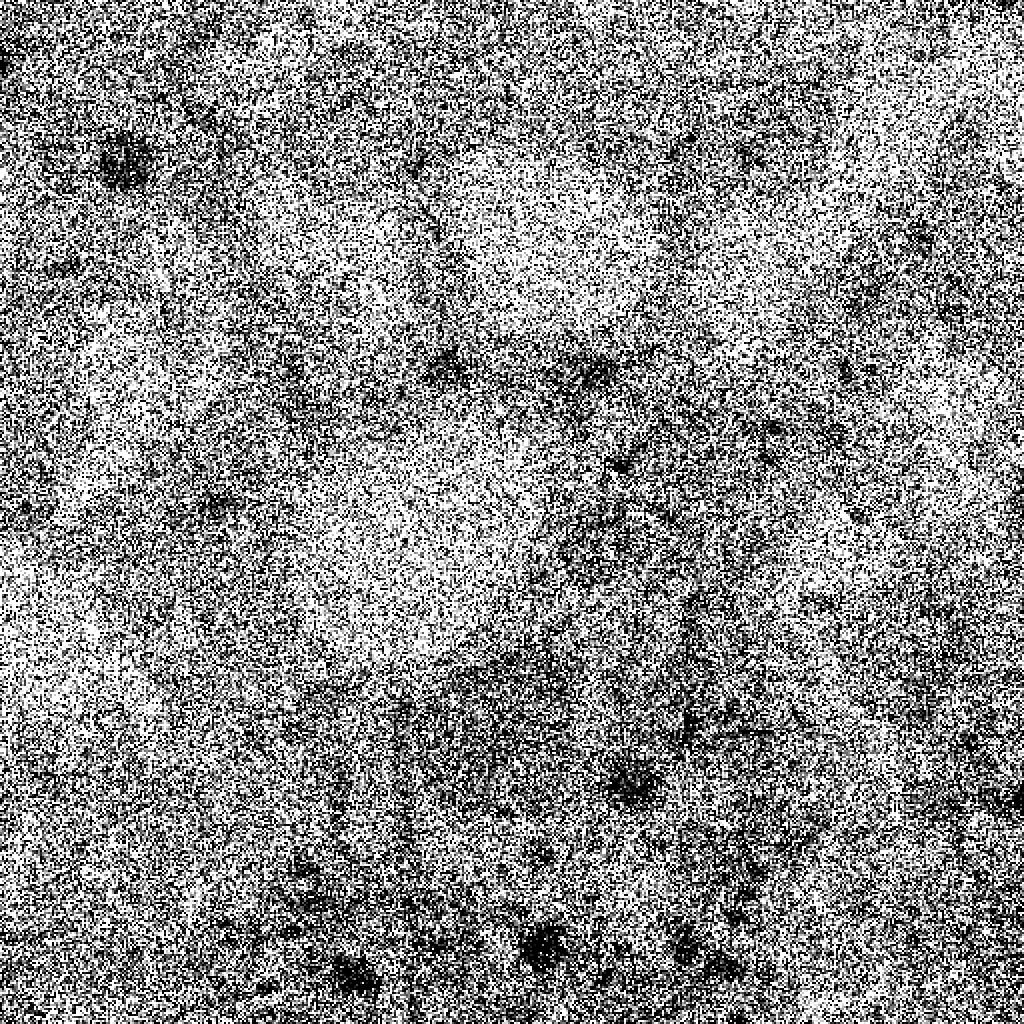</td>
<td align="center"><b>UltraVEM-DN output</b><br>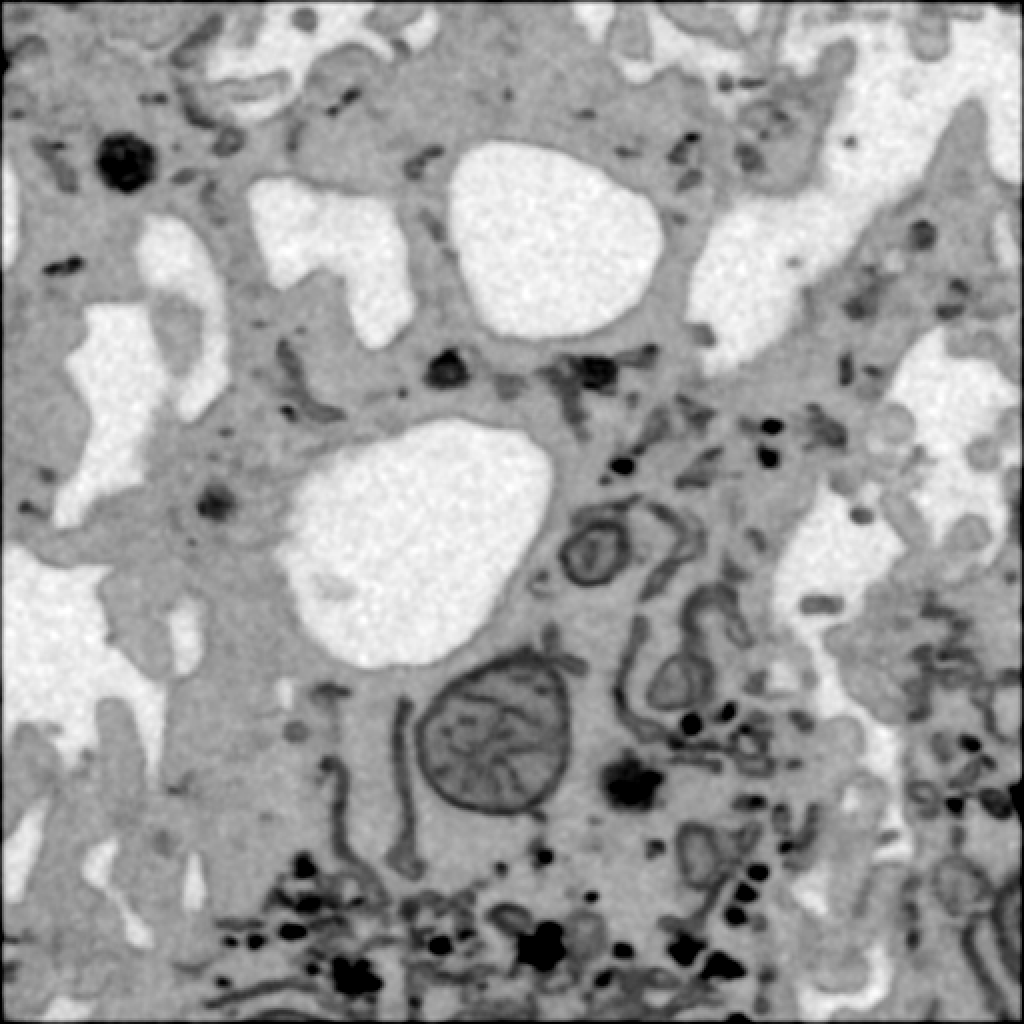</td>
</tr>
</table>

The denoised volume preserves organelle membranes and mitochondrial cristae
while removing the shot- and read-noise present in the short-dwell-time acquisition.

## Summary

An end-to-end UltraVEM-DN workflow:

1. organize clean `.nii.gz` volumes in the nnU-Net raw layout,
2. `nnUNetv2_plan_and_preprocess` once per dataset,
3. `run_training.py -tr nnUNetTrainer_Denoising`, configured through the
   `nnUNet_DN_*` variables,
4. `predict_dn.py` to denoise new volumes,
5. inspect the result in any NIfTI viewer, or with the snippet above.
